# ablation and native export parity: Comparison with published methods

**Level:** 3 **Prerequisites:** Ablations and native export parity level 1 **Reading time:** 25 minutes

**Question:** Do matched ablation outcomes and native export parity establish a component contribution?

## Objectives

This lesson investigates the question: Do matched ablation outcomes and native export parity establish a component contribution?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/research.json` - `docs/evaluation/corrected-results.json` - `data/derived/episodes/M03-C07-nominal-40000; - `data/derived/episodes/M04-C07-nominal-40000; - `data/derived/episodes/M11-C07-nominal-40000; - `data/derived/episodes/M12-C07-nominal-40000;json`

## Method

Ablation is a causal diagnostic only when the task set exposes behavior that depends on the removed component. All four tested M12 ablations match the full method's 1,160 of 1,200 core successes, so this release finds no task-success contribution under its current protocol. Numerical export parity instead asks whether the compiled scorer matches the reference on the measured vectors and thresholds. This comparison runs M04 on the same case but does not convert parity into evidence of useful control, robust calibration or scientific novelty. Numerical export parity asks whether native outputs approximate a reference implementation within a declared tolerance, which is a different estimand from task success or causal contribution. Record the tested input domain, precision, tolerance and worst absolute error; a small maximum error on sampled states does not guarantee safe behavior outside that domain. A strong conclusion separates behavioral ablation, numerical parity and end-to-end task outcomes, and names the evidence each supports without using one as a substitute for another. A useful extension adds inputs near decision boundaries and outside the training range while preserving the tolerance before interpreting parity as deployment evidence.

### ablation and native export parity · level 3 — Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M03", "M04", "M11", "M12"]
trace_methods = ["M03", "M04", "M11", "M12"]
sample_case = "C07"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### ablation and native export parity · level 3 — Execute the released policies and compare the run

### ablation and native export parity · level 3 — Compare the full sequence, not only the first action

### ablation and native export parity · level 3 — Recompute per-variant outcomes from every trace in the case

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M03 boundary successes= 10 episodes= 10 rate= 1.0
M03 delayed_observation successes= 10 episodes= 10 rate= 1.0
M03 duplicate_event successes= 10 episodes= 10 rate= 1.0
M03 nominal successes= 10 episodes= 10 rate= 1.0
M03 stale_conflict successes= 10 episodes= 10 rate= 1.0
M03 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M11 boundary successes= 10 episodes= 10 rate= 1.0
M11 delayed_observation successes= 10 episodes= 10 rate= 1.0
M11 duplicate_event successes= 10 episodes= 10 rate= 1.0
M11 nominal successes= 10 episodes= 10 rate= 1.0
M11 stale_conflict successes= 10 episodes= 10 rate= 1.0
M11 unavailable_dependency successes= 10 episodes= 10

### Plot the variant stress without pooling families

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
display(fig)
plt.close(fig)


<Figure size 900x450 with 1 Axes>

### Recompute the matched ablations

In [5]:
# Research is bound to the canonical index digest and preserves cell-level pairing.
research = json.loads((ROOT / "data/derived/research.json").read_text(encoding="utf-8"))
full = next(row for row in research["core"]["methods"] if row["method_id"] == "M12")
print("Full M12:", full["successes"], "/", full["episodes"], "| rate=", full["success_rate"])
for name, result in research["ablations"].items():
    ablated = next(row for row in result["methods"] if row["method_id"] == "M12")
    paired = result["paired_full_minus_ablation"]
    print(
        name,
        "| successes=",
        ablated["successes"],
        "/",
        ablated["episodes"],
        "| paired delta=",
        paired["success_difference_left_minus_right"],
        "| seed bootstrap95=",
        paired["paired_seed_bootstrap95"],
        "| full-minus-ablation wall ms=",
        round(paired["mean_wall_difference_ms_left_minus_right"], 3),
        "| scope=",
        paired["scope"],
    )


Full M12: 1160 / 1200 | rate= 0.9666666666666667
no_memory | successes= 1160 / 1200 | paired delta= 0.0 | seed bootstrap95= [0.0, 0.0] | full-minus-ablation wall ms= 2.588 | scope= designed shared templates; small seed-group population; compute budgets are not equalized
no_effects | successes= 1160 / 1200 | paired delta= 0.0 | seed bootstrap95= [0.0, 0.0] | full-minus-ablation wall ms= 39.28 | scope= designed shared templates; small seed-group population; compute budgets are not equalized
no_deferral | successes= 1160 / 1200 | paired delta= 0.0 | seed bootstrap95= [0.0, 0.0] | full-minus-ablation wall ms= 131.89 | scope= designed shared templates; small seed-group population; compute budgets are not equalized
no_invalidation | successes= 1160 / 1200 | paired delta= 0.0 | seed bootstrap95= [0.0, 0.0] | full-minus-ablation wall ms= 5.0 | scope= designed shared templates; small seed-group population; compute budgets are not equalized


### Audit M03/M04 numerical parity

In [6]:
# Numerical parity does not establish safety, decision calibration, or generalization.
for method_id, result in research["native_parity"]["results"].items():
    timing = result["warmed_latency_ms"]
    print(
        method_id,
        "| vectors=",
        result["vectors"],
        "| thresholds=",
        result["split_thresholds"],
        "| max error=",
        result["max_abs_probability_error"],
        "<=",
        result["tolerance"],
    )
    print(
        "  warmed p50/p95 ms native=",
        timing["native_cached"]["50"],
        timing["native_cached"]["95"],
        "| Python=",
        timing["python_reference"]["50"],
        timing["python_reference"]["95"],
    )
    print("  scope:", result["warmed_timing_scope"])
print(research["native_parity"]["note"])


M03 | vectors= 484 | thresholds= 76 | max error= 3.1308289294429414e-14 <= 1e-05
  warmed p50/p95 ms native= 0.009 0.0118 | Python= 0.10905000000000001 0.1334849999999999
  scope: Native: packed feature serialization + cached Rust scoring + return list; Python: fitted model predict + Platt; both exclude shared feature construction and effect execution
M04 | vectors= 484 | thresholds= 76 | max error= 3.7825163745619506e-07 <= 1e-05
  warmed p50/p95 ms native= 0.0185 0.0231 | Python= 0.2917 0.38110499999999975
  scope: Native: packed feature serialization + cached Rust scoring + return list; Python: fitted model predict + Platt; both exclude shared feature construction and effect execution
Numerical export parity, not outcome generalization or safety calibration evidence


### ablation and native export parity · L3 — Build the first executable policy

In level 3, construct policy M03 for ablation and native export parity with the public factory and keep its observation contract unchanged before sampling C07.

In [7]:
# Construct the first released policy through the public factory.
primary_id = "M03"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M03


### ablation and native export parity · L3 — Execute the primary method on the named case

For the ablation and native export comparator run on C07, the ablation and native export parity evaluator runs M03 on C07 and derives success from the independent task postcondition, not from a replayed trace.

In [8]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### ablation and native export parity · L3 — Construct an independent comparison policy

Within this ablation and native export comparison (C07), create M04 as a fresh object so recurrent state from M03 cannot leak into the matched comparison.

In [9]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M04"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### ablation and native export parity · L3 — Run the comparison under identical conditions

This level 3 comparison runs M04 on the same C07, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [10]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### ablation and native export parity · L3 — Aggregate the two executed episodes

Within this ablation and native export comparison (C07), the package aggregator summarizes two executed ablation and native export parity episodes, and cross-family claims still require the complete benchmark below.

In [11]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### ablation and native export parity · L3 — Fresh policy outcomes

In the matched ablation and native export comparison on C07, the next plot is computed from the ablation and native export parity episode results just executed for C07 rather than copied from a frozen artifact.

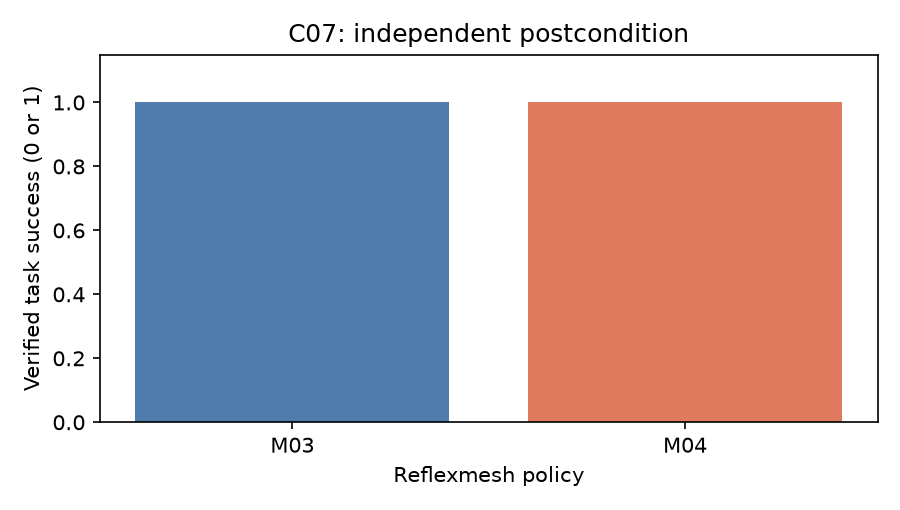

In [12]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


In the matched ablation and native export comparison on C07, for ablation and native export parity, these bars show fresh task-postcondition outcomes for M03 and M04 on C07, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the matched ablation and native export comparison on C07, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

## Comparison
Ablation is a causal diagnostic only when the task set exposes behavior that depends on the removed component.

This 06 ablation and export parity lesson, interprets only its declared software case and seed. For the ablation and native export comparator run on C07, the executed policy's score does not grant authority: For the ablation and native export comparator run on C07, an independent environment check determines whether the requested postcondition was met. In the matched ablation and native export comparison on C07, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. For the ablation and native export comparator run on C07, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. For the ablation and native export comparator run on C07, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; In the matched ablation and native export comparison on C07, failures and cancellations stay in their original denominators. For the ablation and native export comparator run on C07, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. For the ablation and native export comparator run on C07, readers can change the case or seed and observe where the inference stops applying.

For 06 ablation and export parity begin by distinguishing policy preference from action authority. For the ablation and native export comparator run on C07, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. In this 06 ablation and export parity example, inspect the episode result together with decision latency; For the ablation and native export comparator run on C07, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. For the ablation and native export comparator run on C07, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. The 06 ablation and export parity measurements cover the recorded software tasks and their frozen protocol. For the ablation and native export comparator run on C07, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. Within this ablation and native export comparison (C07), use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. This makes the 06 ablation and export parity exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### ablation and native export parity · L3 — Execute the XGBoost reference on matched conditions

This level 3 ablation and native export parity reference call executes M04 on C07 with the same nominal seed as the fresh policies, and its score and time form one matched observation.

In [13]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


### ablation and native export parity · L3 | Recorded controller time

In the matched ablation and native export comparison on C07, the ablation and native export parity timing chart uses hash-verified frozen records for M03 and M04 on C07, not machine-dependent timings from fresh episodes. This level 3 ablation and native export parity view describes the recorded environment under its declared case, variant and seed.

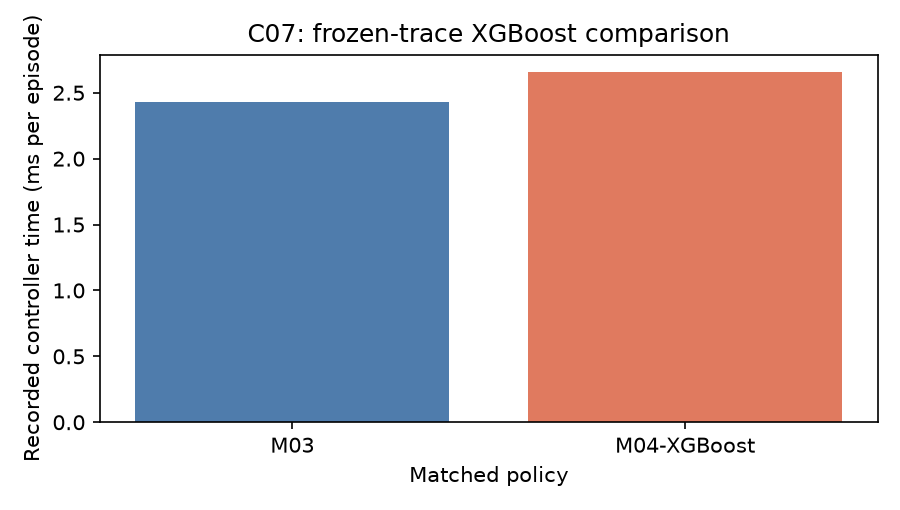

In [14]:
# Compare hash-verified canonical controller times under the same case, variant and seed.
labels = [primary_id, "M04-XGBoost"]
latencies = [records[primary_id]["metrics"]["controller_ms"], records["M04"]["metrics"]["controller_ms"]]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Matched policy")
ax.set_title(f"{sample_case}: frozen-trace XGBoost comparison")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 ablation and native export parity chart reads canonical M03/M04 records for C07, nominal variant and seed 40000 after the data boundary verifies their hashes. In the matched ablation and native export comparison on C07, for this ablation and native export parity lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The ablation and native export parity level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C07; those 3 matched runs do not establish population-level superiority for ablation and native export parity.

For the ablation and native export comparator run on C07, all four ablations preserve the same 1,160/1,200 task successes, so this experiment does not show success contribution by memory, effects, deferral or invalidation; In the matched ablation and native export comparison on C07, runtime budgets differ across variants, and measured export timings exclude Python feature construction; Numerical parity is not policy safety calibration.

## Summary

Within this ablation and native export comparison (C07), this ablation and native export parity example uses C07 to show behavior under one declared condition. For the ablation and native export comparator run on C07, keep the measured outcome separate from claims about broader software-control intelligence.



## References
- [XGB](https://arxiv.org/abs/1603.02754) - [PPO](https://arxiv.org/abs/1707.06347)